In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
# Connect and Access Git Repository

import sys
from getpass import getpass
from pathlib import Path

GITHUB_USERNAME = "sharaffatima"
REPO_NAME = "bachelor-thesis"



token = getpass("GitHub token: ")


REPO_URL = f"https://{token}@github.com/{GITHUB_USERNAME}/{REPO_NAME}.git"
REPO_DIR = Path("/content") / REPO_NAME


if not REPO_DIR.exists():
    !git clone {REPO_URL} {REPO_DIR}
else:
    %cd {REPO_DIR}
    !git pull

%cd {REPO_DIR}
sys.path.append(str(REPO_DIR))

print("Repo exists:", REPO_DIR.exists())


GitHub token: ··········
Cloning into '/content/bachelor-thesis'...
remote: Enumerating objects: 435, done.
remote: Counting objects: 100% (171/171), done.
remote: Compressing objects: 100% (142/142), done.
remote: Total 435 (delta 92), reused 65 (delta 28), pack-reused 264 (from 1)
Receiving objects: 100% (435/435), 26.70 MiB | 16.62 MiB/s, done.
Resolving deltas: 100% (209/209), done.
/content/bachelor-thesis
Repo exists: True


In [ ]:
!pip install -q shap

In [4]:
# Imports
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import shap
from torch.utils.data import DataLoader



# global configuration

REPO_DIR = Path("/content/bachelor-thesis")
sys.path.append(str(REPO_DIR))


from utils.seed import set_seed, RANDOM_SEED
from models.anoformer import AnoFormerMainModel
from utils.dataset import PTBXLAnoFormerDataset
from explainability.anomaly_score_wrappers import AnoFormerAnomalyScoreWrapper
from explainability.shap_explainer import aggregate_shap_intervals, plot_normal_anomalous_shap_heatmaps
from explainability.evaluation import plot_temporal_explanation


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
set_seed(RANDOM_SEED)
print(f"Active device: {DEVICE}")

Active device: cuda


In [5]:
# Paths

DATA_DIR = Path("/content/drive/MyDrive/ECG data")
PROCESSED_DIR = DATA_DIR / "processed"
RESULTS_DIR = DATA_DIR / "results"

MODEL_DIR = RESULTS_DIR / "models" / "anoformer"

MODEL_PATH = MODEL_DIR / "anoformer_40epochs_larger_capacity.pt"

SHAP_RESULTS_DIR = RESULTS_DIR / "shap"
SHAP_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

EXPLANATION_SAMPLES_PATH = RESULTS_DIR / "evaluation" / "shared_explanation_samples.npz"


print("MODEL_PATH:", MODEL_PATH)
print("SHAP results:", SHAP_RESULTS_DIR)
print("Shared explanation samples:", EXPLANATION_SAMPLES_PATH)

MODEL_PATH: /content/drive/MyDrive/ECG data/results/models/anoformer/anoformer_40epochs_larger_capacity.pt
SHAP results: /content/drive/MyDrive/ECG data/results/shap
Shared explanation samples: /content/drive/MyDrive/ECG data/results/evaluation/shared_explanation_samples.npz


In [6]:
# Load my preprocessed data

X_train = np.load(PROCESSED_DIR / "X_train.npy")
y_train = np.load(PROCESSED_DIR / "y_train.npy")

X_val = np.load(PROCESSED_DIR / "X_val.npy")
y_val = np.load(PROCESSED_DIR / "y_val.npy")

X_test = np.load(PROCESSED_DIR / "X_test.npy")
y_test = np.load(PROCESSED_DIR / "y_test.npy")

print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)
print(X_test.shape, y_test.shape)

(17418, 1000, 12) (17418,)
(2183, 1000, 12) (2183,)
(2198, 1000, 12) (2198,)


In [7]:
# Training only on normal data

normal_train_mask = y_train == 0

X_train_normal = X_train[normal_train_mask]
y_train_normal = y_train[normal_train_mask]

print("Training on normal ECGs:", X_train_normal.shape)

Training on normal ECGs: (7596, 1000, 12)


In [8]:
# Datasets

train_dataset = PTBXLAnoFormerDataset(
    X_train_normal,
    y_train_normal,
    normalize=True
)

val_dataset = PTBXLAnoFormerDataset(
    X_val,
    y_val,
    mean=train_dataset.mean,
    std=train_dataset.std,
    normalize=True
)

test_dataset = PTBXLAnoFormerDataset(
    X_test,
    y_test,
    mean=train_dataset.mean,
    std=train_dataset.std,
    normalize=True
)

In [9]:
# Dataloaders

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    drop_last=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [10]:
AnoFormer = AnoFormerMainModel(
    NumFeatures=12,
    ModelDimension=64,
    NumHeads=4,
    NumEncoderLayers=2,
    NumDecoderLayers=2,
    DiscriminatorLayers=1,
    ForwardDimension=128,
    DropoutRate=0.1,
    GeneratorLearningRate=1e-4,
    DiscriminatorLearningRate=1e-4,
    MaskingRate=0.15,
    AnomalyThreshold=0.75,
    ReconstructionWeight=10.0,
)

In [11]:
# Load the pre-trained model

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Model checkpoint not found: {MODEL_PATH}"
    )

AnoFormer.Load(str(MODEL_PATH))
AnoFormer.Generator.to(DEVICE)
AnoFormer.Generator.eval()

print("AnoFormer checkpoint loaded.")

Modell geladen von: /content/drive/MyDrive/ECG data/results/models/anoformer/anoformer_40epochs_larger_capacity.pt
AnoFormer checkpoint loaded.


In [12]:
# Create the Score Wrapper

ScoreWrapper = AnoFormerAnomalyScoreWrapper(
    anoformer_model=AnoFormer,
    window_size=1000,
    masking_rate=None,  # Uses the rate stored in AnoFormer.Masking
    num_masks=1, #try 3 later
    seed=RANDOM_SEED,
).to(DEVICE)

ScoreWrapper.eval()

AnoFormerAnomalyScoreWrapper(
  (generator): TransformerGenerator(
    (InputEmbedding): InputEmbeddingLayer(
      (ProjectionLayer): Linear(in_features=12, out_features=64, bias=True)
      (ActivationReLU): ReLU()
    )
    (PositionalEncoding): PositionalEncoding(
      (DropoutLayer): Dropout(p=0.1, inplace=False)
    )
    (EncoderStack): TransformerEncoderStack(
      (EncoderBlockList): ModuleList(
        (0-1): 2 x TransformerEncoderBlock(
          (SelfAttention): MultiHeadAttention(
            (LinearLayerQuery): Linear(in_features=64, out_features=64, bias=False)
            (LinearLayerKey): Linear(in_features=64, out_features=64, bias=False)
            (LinearLayerValue): Linear(in_features=64, out_features=64, bias=False)
            (LinearLayerOutput): Linear(in_features=64, out_features=64, bias=True)
            (AttentionDropoutLayer): Dropout(p=0.1, inplace=False)
          )
          (NormalizationOne): LayerNormalization()
          (ForwardNetworkLayer): Fo

In [13]:
# Select Background ECG samples from training set for SHAP

BACKGROUND_SIZE = 50

normal_train_indices = np.where(y_train == 0)[0]

rng = np.random.default_rng(RANDOM_SEED)

background_indices = rng.choice(
    normal_train_indices,
    size=BACKGROUND_SIZE,
    replace=False,
)

background_ECGs = torch.as_tensor(
    X_train[background_indices],
    dtype=torch.float32,
    device=DEVICE,
)

print("Background shape:", background_ECGs.shape)
print("Background labels:", y_train[background_indices])

Background shape: torch.Size([50, 1000, 12])
Background labels: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [14]:
# Save the background indices so the same samples can be used for TranAD SHAP explaination too

np.save(
    SHAP_RESULTS_DIR / "medium_background_indices.npy",
    background_indices,
)

In [15]:
# select ECG samples to explain with SHAP
# I choose the same two samples I used in the Anoformer Attention explanation experiment

SharedSamples = np.load(
    RESULTS_DIR
    / "evaluation"
    / "shared_explanation_samples.npz"
)

NormalIndex = int(
    SharedSamples["normal_index"]
)

AnomalousIndex = int(
    SharedSamples["anomalous_index"]
)

NormalECG, NormalLabel = test_dataset[NormalIndex]
AnomalousECG, AnomalousLabel = test_dataset[AnomalousIndex]

NormalECG = NormalECG.unsqueeze(0).to(AnoFormer.Device)
AnomalousECG = AnomalousECG.unsqueeze(0).to(AnoFormer.Device)

print("Index of Normal ECG:", NormalIndex, "Label:", NormalLabel.item())
print("Index of Anomalous ECG:", AnomalousIndex, "Label:", AnomalousLabel.item())
print("Anomalous index:", AnomalousIndex)

Index of Normal ECG: 583 Label: 0
Index of Anomalous ECG: 495 Label: 1
Anomalous index: 495


In [16]:
sample_indices = np.array(
    [NormalIndex, AnomalousIndex]
)

sample_ECGs = torch.as_tensor(
    X_test[sample_indices],
    dtype=torch.float32,
    device=DEVICE,
)

sample_Labels = y_test[sample_indices]

print("ECG shape:", sample_ECGs.shape)
print("Labels:", sample_Labels)

ECG shape: torch.Size([2, 1000, 12])
Labels: [0 1]


In [19]:
# create a GradientSHAPEplainer and calculate the SHAP values

GradientSHAPExplainer = shap.GradientExplainer(
    ScoreWrapper,
    background_ECGs,
)

SHAPValues = GradientSHAPExplainer.shap_values(
    sample_ECGs
)

In [20]:
# Remove the single-output dimension if it exists:
# (2, 1000, 12, 1) -> (2, 1000, 12)

if SHAPValues.ndim == 4 and SHAPValues.shape[-1] == 1:
    SHAPValues = SHAPValues[..., 0]

print("SHAP shape:", SHAPValues.shape)

SHAP shape: (2, 1000, 12)


In [21]:
print("Contains NaN:", np.isnan(SHAPValues).any())
print("Contains infinity:", np.isinf(SHAPValues).any())
print("All values zero:", np.allclose(SHAPValues, 0))

print("Minimum:", SHAPValues.min())
print("Maximum:", SHAPValues.max())
print("Mean absolute value:", np.abs(SHAPValues).mean())

Contains NaN: False
Contains infinity: False
All values zero: False
Minimum: -0.0003568154477565352
Maximum: 0.0018918019269453317
Mean absolute value: 4.521323167612211e-06


In [39]:
# aggregate the values for better plots

NormalSHAPIntervals = aggregate_shap_intervals(
    SHAPValues[0],
    block_size=10,
    absolute=True,
)

AnomalousSHAPIntervals = aggregate_shap_intervals(
    SHAPValues[1],
    block_size=10,
    absolute=True,
)

print(NormalSHAPIntervals.shape)
print(AnomalousSHAPIntervals.shape)

(100, 12)
(100, 12)


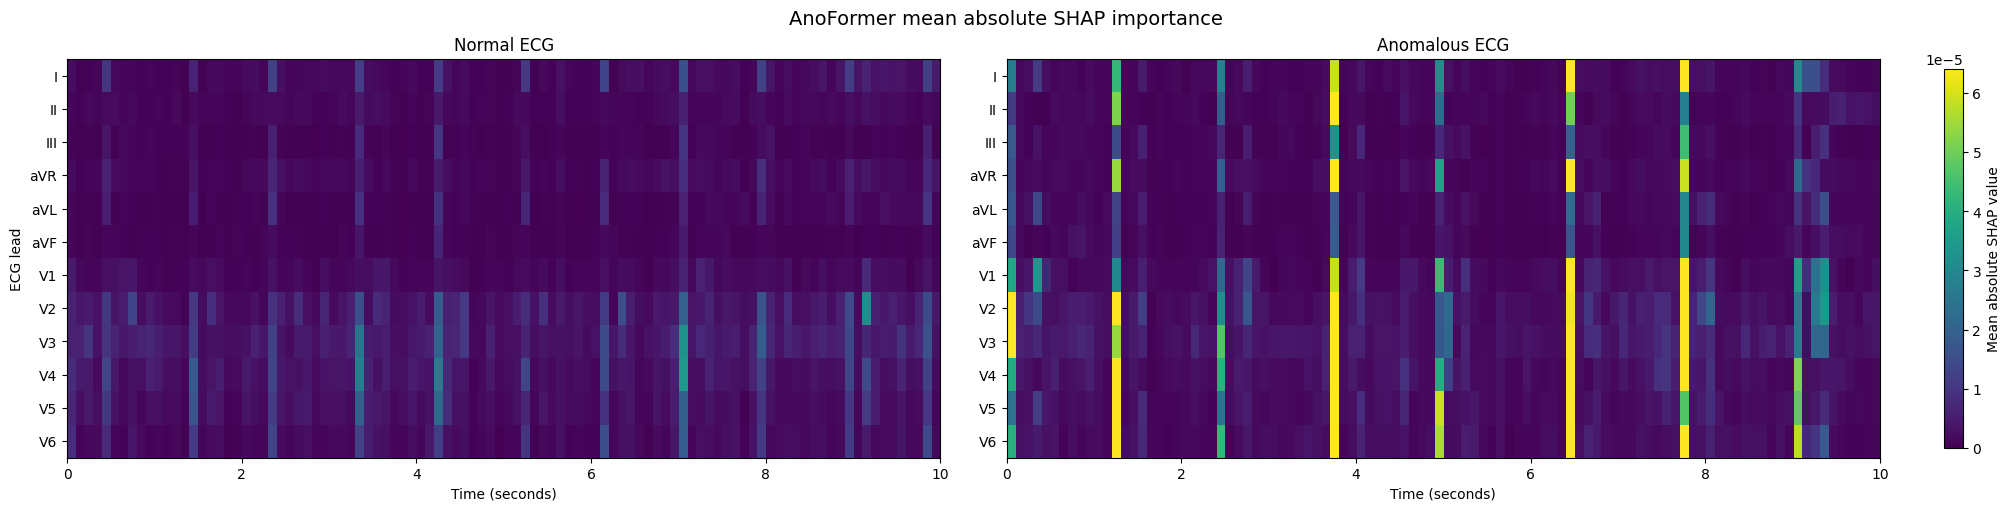

In [59]:
# Plot SHAP Heatmaps

LEAD_NAMES = [
    "I", "II", "III",
    "aVR", "aVL", "aVF",
    "V1", "V2", "V3",
    "V4", "V5", "V6",
]

plot_normal_anomalous_shap_heatmaps(
    normal_values=NormalSHAPIntervals,
    anomalous_values=AnomalousSHAPIntervals,
    lead_names=LEAD_NAMES,
    interval_seconds=0.1,
    percentile=99.0,
    save_path=(
        SHAP_RESULTS_DIR
        / "anoformer"
        / "shap_normal_vs_anomalous.png"
    ),
)

In [ ]:
NormalTemporalSHAP = NormalSHAPIntervals.mean(axis=1)
AnomalousTemporalSHAP = AnomalousSHAPIntervals.mean(axis=1)

print(NormalTemporalSHAP.shape)
print(AnomalousTemporalSHAP.shape)

In [ ]:
# Plot that is comparable with the Attention plot

plot_temporal_explanation(
    importance=NormalTemporalSHAP,
    title="AnoFormer SHAP temporal importance — normal ECG",
    interval_seconds=0.1,
    save_path=(
        SHAP_RESULTS_DIR
        / "anoformer"
        / "temporal_shap_normal.png"
    ),
)

plot_temporal_explanation(
    importance=AnomalousTemporalSHAP,
    title="AnoFormer SHAP temporal importance — anomalous ECG",
    interval_seconds=0.1,
    save_path=(
        SHAP_RESULTS_DIR
        / "anoformer"
        / "temporal_shap_anomalous.png"
    ),
)